# Project: Financial Inclusion In East Africa

- Author: Patrick Tuyizere
- Github:
- Demo Video: https://www.loom.com/share/dd73deb8ee1544188a53212b3cbb69fe

## Section 1: Project Overview
Financial inclusion means that individuals have access to affordable and effective financial products and services. That is they can transact, pay, save, and access credit delivered by responsible financial institutions like banks.
At its core, this project aims to assess the level of financial inclusion in Kenya, Uganda, Tanzania and Rwanda by building models that predict which individuals are likely to have or use a bank account.
We use the **Financial Inclusion In Africa** dataset, originally published through a Zindi competition and available on Kaggle. The dataset contains survey answers from the aforementioned countries. Our chosen target variable is `bank_account`, which is a binary ("Yes" or "No") on whether the survey participant has a bank account. So all in all the goal is to predict the probability that a participant has a bank account using demographic and socioeconomic features.

## Section 2: Environment setup and imports

In [41]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
)
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.base import clone
from scipy.stats import randint
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.model_selection import learning_curve
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import roc_curve, precision_recall_curve

from tensorflow import keras
from tensorflow.keras import regularizers

import joblib
import shutil

# Setting random seeds for reproducibility
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# package import verification
print("pandas version:", pd.__version__)
print("numpy version:", np.__version__)
print("scikit-learn version:", sklearn.__version__)
print("tensorflow version:", tf.__version__)

pandas version: 2.2.3
numpy version: 2.1.3
scikit-learn version: 1.6.1
tensorflow version: 2.21.0


## Section 3: Loading the dataset
First we connect to google drive before loading the dataset.

In [5]:
from google.colab import drive

drive.mount("/content/drive", force_remount=True)

DATA_PATH = "/content/drive/MyDrive/ml_summative/Train.csv"
df = pd.read_csv(DATA_PATH)
print("Dataset successfully loaded")
print("Shape of the dataset: ", df.shape)
display(df.head())

Mounted at /content/drive
Dataset successfully loaded
Shape of the dataset:  (23524, 13)


,country,year,uniqueid,bank_account,location_type,cellphone_access,household_size,age_of_respondent,gender_of_respondent,relationship_with_head,marital_status,education_level,job_type
0,Kenya,2018,uniqueid_1,Yes,Rural,Yes,3,24,Female,Spouse,Married/Living together,Secondary education,Self employed
1,Kenya,2018,uniqueid_2,No,Rural,No,5,70,Female,Head of Household,Widowed,No formal education,Government Dependent
2,Kenya,2018,uniqueid_3,Yes,Urban,Yes,5,26,Male,Other relative,Single/Never Married,Vocational/Specialised training,Self employed
3,Kenya,2018,uniqueid_4,No,Rural,Yes,5,34,Female,Head of Household,Married/Living together,Primary education,Formally employed Private
4,Kenya,2018,uniqueid_5,No,Urban,No,8,26,Male,Child,Single/Never Married,Primary education,Informally employed


## Section 4: Dataset analysis

Column names:
['country', 'year', 'uniqueid', 'bank_account', 'location_type', 'cellphone_access', 'household_size', 'age_of_respondent', 'gender_of_respondent', 'relationship_with_head', 'marital_status', 'education_level', 'job_type']

Data types:
country                   object
year                       int64
uniqueid                  object
bank_account              object
location_type             object
cellphone_access          object
household_size             int64
age_of_respondent          int64
gender_of_respondent      object
relationship_with_head    object
marital_status            object
education_level           object
job_type                  object
dtype: object

Missing values per column:
country                   0
year                      0
uniqueid                  0
bank_account              0
location_type             0
cellphone_access          0
household_size            0
age_of_respondent         0
gender_of_respondent      0
relationship_with_head    0

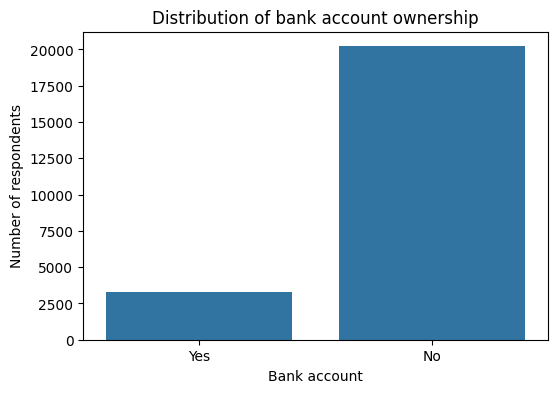

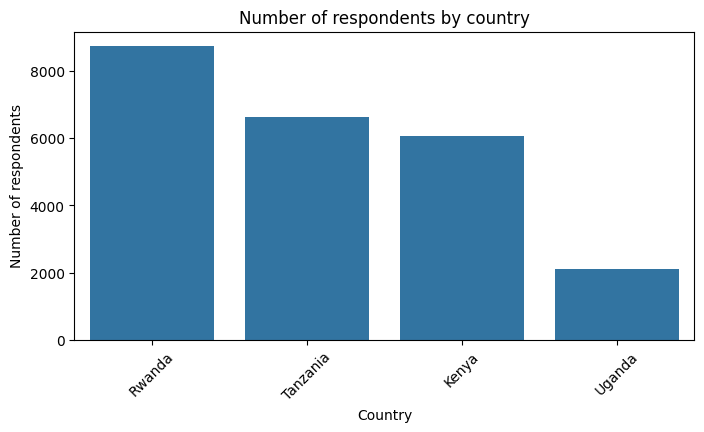


Proportion with a bank account by country:
country
Kenya       0.251
Rwanda      0.115
Tanzania    0.092
Uganda      0.086
Name: bank_account_binary, dtype: float64


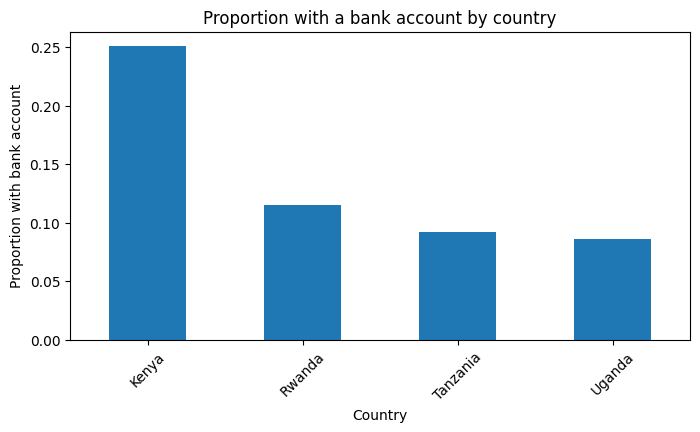

In [6]:
# Column names and data types
print("Column names:")
print(df.columns.tolist())
print("\nData types:")
print(df.dtypes)

# Missing values
print("\nMissing values per column:")
print(df.isnull().sum())

# Duplicate rows
print("\nNumber of duplicate rows:", df.duplicated().sum())

# Target distribution
print("\nTarget distribution (counts):")
print(df["bank_account"].value_counts())
print("\nTarget distribution (proportions):")
print(df["bank_account"].value_counts(normalize=True).round(3))

# Country distribution
print("\nCountry distribution:")
print(df["country"].value_counts())

# Visualising the target distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="bank_account")
plt.title("Distribution of bank account ownership")
plt.xlabel("Bank account")
plt.ylabel("Number of respondents")
plt.show()

# Visualising country distribution
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x="country", order=df["country"].value_counts().index)
plt.title("Number of respondents by country")
plt.xlabel("Country")
plt.ylabel("Number of respondents")
plt.xticks(rotation=45)
plt.show()

# Bank account rates by country
country_rate = (
  df.assign(bank_account_binary=(df["bank_account"] == "Yes").astype(int))
  .groupby("country")["bank_account_binary"]
  .mean()
  .sort_values(ascending=False)
)
print("\nProportion with a bank account by country:")
print(country_rate.round(3))

plt.figure(figsize=(8, 4))
country_rate.plot(kind="bar")
plt.title("Proportion with a bank account by country")
plt.xlabel("Country")
plt.ylabel("Proportion with bank account")
plt.xticks(rotation=45)
plt.show()

- From the output we can see that the dataset doesn't have any missing values in nay of the columns and no duplicates
- But from the plots we can also see a clear class imbalance where around 14% of the participants said "Yes" and 86% "No". The implications of this is that even a model that always predicts "No" no matter the input, could still have an accuracy of 86%. Therefore it is crucial that we don't rely on model accuracy too much as it can be misleading.
- The coutry ploting also reveals an imbalance where Kenya is overwhelingly represented and will be relevant for subgroup analysis later on.

## Section 5: Data preprocessing
The `uniqueid` column is just an identifier that has no actual relevance to the core problem we trying to solve and has not generalizable information. In other words the column plays no role in whether a given subject has a bank account or not
The ramaining features are mostly categorical. We shall use the `OneHotEncoder` to encode those. As for the numerical features are imputed with the median and scaled with `StandardScaler`.
We then use `ColumnTransformer` to ensure that the same transformations happend to all splits.

In [7]:
# Separate the target and remove the identifier
y = df["bank_account"].map({"Yes": 1, "No": 0})
X = df.drop(columns=["bank_account", "uniqueid"])

# Define numerical and categorical columns
numerical_cols = ["household_size", "age_of_respondent", "year"]
categorical_cols = [
  "country",
  "location_type",
  "cellphone_access",
  "gender_of_respondent",
  "relationship_with_head",
  "marital_status",
  "education_level",
  "job_type",
]

# Numerical pipeline: impute missing values with the median, then scale
numerical_pipeline = Pipeline(steps=[
  ("imputer", SimpleImputer(strategy="median")),
  ("scaler", StandardScaler()),
])

# Categorical pipeline: impute missing values with the most frequent value,
# then one-hot encode
categorical_pipeline = Pipeline(steps=[
  ("imputer", SimpleImputer(strategy="most_frequent")),
  ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

# Combine both pipelines
preprocessor = ColumnTransformer(transformers=[
  ("num", numerical_pipeline, numerical_cols),
  ("cat", categorical_pipeline, categorical_cols),
])

print("Preprocessing pipeline created.")
print("Numerical columns:", numerical_cols)
print("Categorical columns:", categorical_cols)

Preprocessing pipeline created.
Numerical columns: ['household_size', 'age_of_respondent', 'year']
Categorical columns: ['country', 'location_type', 'cellphone_access', 'gender_of_respondent', 'relationship_with_head', 'marital_status', 'education_level', 'job_type']


## Section 6: Train, Validation, Test Splitting
The dataset is split in 60% training, 20% validation, and 20% test.

In [8]:
# First split: separate training (60%) from the rest (40%)
X_train, X_temp, y_train, y_temp = train_test_split(
  X,
  y,
  test_size=0.40,
  stratify=y,
  random_state=SEED,
)

# Second split: divide the remaining 40% into validation (20%) and test (20%)
X_val, X_test, y_val, y_test = train_test_split(
  X_temp,
  y_temp,
  test_size=0.50,
  stratify=y_temp,
  random_state=SEED,
)

print("Training set size:", X_train.shape[0])
print("Validation set size:", X_val.shape[0])
print("Test set size:", X_test.shape[0])

print("\nPositive proportion in training set:", round(y_train.mean(), 3))
print("Positive proportion in validation set:", round(y_val.mean(), 3))
print("Positive proportion in test set:", round(y_test.mean(), 3))

Training set size: 14114
Validation set size: 4705
Test set size: 4705

Positive proportion in training set: 0.141
Positive proportion in validation set: 0.141
Positive proportion in test set: 0.141


- Given the aforementioned class imbalance, we used a strtified splitting approach to preserve the proportion of Yes and No examples in each subset. This is important to make sure that the test or validation subsets don't end up with very few Yes examples or none at all which would make our evaluation unstable and inaccurate.

## Section 7: Evaluation Metrics

The fact that the positive/yes class is rare, measuring model accuracy alone would be misleading. The project therefore reports the following metrics:
- **Accuracy**: Overall proportion of correct predictions.
- **Precision**: Of all the participants predict to have a bank account, precision measures the proportion of those that actually do.
- **Recall/Sensitivity**: Of all the participants that have a bank account, recall tells us the proportion of those that were correctly identified.
- **F1-score**: Mean of precision and recall.
- **ROC-AUC**: This tells the probability that a given positive example has high predicted probability than a random negative example.
- **Average precision**: This is the area under the precision-recall curve. Given that class imbalance makes accuracy a poor metric, average precision gives a better picture of a model's performance by focusing the positive class and rewards a model that ranks true positives higher false positives.
- **Confusion Matrix**: This is the table that helps to visualize true positives, true negatives, false positives, and false negatives.

## Section 8: Logistic Regression Baseline

In [9]:
# Define a helper function to evaluate a fitted model on a dataset
def evaluate_model(model, X_data, y_true, dataset_name="dataset"):
  y_pred = model.predict(X_data)
  y_prob = model.predict_proba(X_data)[:, 1]

  results = {
    "dataset": dataset_name,
    "accuracy": accuracy_score(y_true, y_pred),
    "precision": precision_score(y_true, y_pred, zero_division=0),
    "recall": recall_score(y_true, y_pred, zero_division=0),
    "f1": f1_score(y_true, y_pred, zero_division=0),
    "roc_auc": roc_auc_score(y_true, y_prob),
    "average_precision": average_precision_score(y_true, y_prob),
  }
  return results

def print_metrics(results, title="Results"):
  print(title)
  for metric, value in results.items():
    if metric == "dataset":
      continue
    print(f"{metric}: {value:.4f}")
  print()

# Baseline pipeline
baseline_lr = Pipeline(steps=[
  ("preprocessor", preprocessor),
  ("classifier", LogisticRegression(max_iter=1000, random_state=SEED)),
])

# Fit on the training set
baseline_lr.fit(X_train, y_train)

# Evaluate on the validation set
baseline_val_results = evaluate_model(
  baseline_lr, X_val, y_val, dataset_name="validation"
)

print_metrics(baseline_val_results,
              title="Baseline Logistic Regression - Val Results:"
)

# Classification report
y_val_pred_baseline = baseline_lr.predict(X_val)
print("\nClassification report (validation):")
print(classification_report(y_val, y_val_pred_baseline, target_names=["No", "Yes"]))

Baseline Logistic Regression - Val Results:
accuracy: 0.8797
precision: 0.6422
recall: 0.3303
f1: 0.4363
roc_auc: 0.8570
average_precision: 0.5545


Classification report (validation):
              precision    recall  f1-score   support

          No       0.90      0.97      0.93      4042
         Yes       0.64      0.33      0.44       663

    accuracy                           0.88      4705
   macro avg       0.77      0.65      0.68      4705
weighted avg       0.86      0.88      0.86      4705



- From the results we can see that the overall accuracy although seemingly somewhat high at 87%, it is important to note that it only marginally better than just always predicting No, which we established earlier would show an accuracy of 86% due to the class imbalance.
- Most notably the recall for the positive class is very low at 33%. This happens because logistic regression is biased towards the majority class.
- By using class-weighted logistic regression, we can ensure that the model heavily penalizes mistakes on the minority class, mitigating the imbalance as a result.

## Section 9: Class-Weighted Logstic Regression

In [28]:
# Class-weighted pipeline
weighted_lr = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=SEED
    ))
])

# Fit on the training set
weighted_lr.fit(X_train, y_train)

# Evaluate on the validation set
weighted_val_results = evaluate_model(
    weighted_lr, X_val, y_val, dataset_name="validation"
)

print_metrics(weighted_val_results,
              title="Class-Weighted Logistic Regression - Val Results:")

y_val_pred_weighted = weighted_lr.predict(X_val)
print("\nClassification report (Validation):")
print(classification_report(y_val, y_val_pred_weighted, target_names=["No", "Yes"]))

Class-Weighted Logistic Regression - Val Results:
accuracy: 0.7868
precision: 0.3731
recall: 0.7541
f1: 0.4993
roc_auc: 0.8569
average_precision: 0.5532


Classification report (Validation):
              precision    recall  f1-score   support

          No       0.95      0.79      0.86      4042
         Yes       0.37      0.75      0.50       663

    accuracy                           0.79      4705
   macro avg       0.66      0.77      0.68      4705
weighted avg       0.87      0.79      0.81      4705



- Compared to the logistic regression model, class weighted logistic regression managed to increase the recall of the positive class from 33% to 75%. However, precision also fell from 64% to 37%. This is because class weighted logistic regression doesn't guarantee improved performance all round. It changes the balance between precision and recall.

## Section 10: Random Forest
Random Forest is a machine learning algorithm that combines multiple decision trees to arrive at a single prediction.

For random forest, the hyperparameters chosen are as follows:
- `n_estimators=200`: This determines the total number of decision trees.
- `random_state=SEED`: Random state controls the randomness of the random forest algorithm and setting it to SEED ensures reproducability.
- `n_jobs=-1`: This hyperparamter controls the number of CPU cores that can be used.

In [29]:
# Build the Random Forest pipeline
rf_model = Pipeline(steps=[
  ("preprocessor", clone(preprocessor)),
  ("classifier", RandomForestClassifier(
      n_estimators=200,
      random_state=SEED,
      n_jobs=-1,
  )),
])

# Fit on the training set
rf_model.fit(X_train, y_train)

# Evaluate on the validation set
rf_val_results = evaluate_model(rf_model, X_val, y_val, dataset_name="validation")

print_metrics(rf_val_results,
              title="Random Forest — Validation results:"
)

y_val_pred_rf = rf_model.predict(X_val)
print("\nClassification report (validation):")
print(classification_report(y_val, y_val_pred_rf, target_names=["No", "Yes"]))

Random Forest — Validation results:
accuracy: 0.8612
precision: 0.5096
recall: 0.3997
f1: 0.4480
roc_auc: 0.8146
average_precision: 0.4839


Classification report (validation):
              precision    recall  f1-score   support

          No       0.90      0.94      0.92      4042
         Yes       0.51      0.40      0.45       663

    accuracy                           0.86      4705
   macro avg       0.71      0.67      0.68      4705
weighted avg       0.85      0.86      0.85      4705



- From the results we can see that compared to the logistic regression, we see a broader improvement on both the negative and positive classes. This general improvement accross most metrics is due to the fact that unlinke logistic regression, random forest is able to capture nonlinear stractures.

## Section 11: Extremely Randomized Trees
Closely related to random forest but extremely randomized trees will select split points at random rather than searching for the optimal points through gini impurity or entropy like random forest does.

For the hyperparameters, we use the same as the random forest model.

In [30]:
# Extra Trees pipeline
et_model = Pipeline(steps=[
  ("preprocessor", clone(preprocessor)),
  ("classifier", ExtraTreesClassifier(
      n_estimators=200,
      random_state=SEED,
      n_jobs=-1,
  )),
])

# Fit on the training set
et_model.fit(X_train, y_train)

# Evaluate on the validation set
et_val_results = evaluate_model(et_model, X_val, y_val, dataset_name="validation")

print_metrics(et_val_results,
              title="Extremely Randomized Trees — Validation results:")

y_val_pred_et = et_model.predict(X_val)
print("\nClassification report (validation):")
print(classification_report(y_val, y_val_pred_et, target_names=["No", "Yes"]))

Extremely Randomized Trees — Validation results:
accuracy: 0.8504
precision: 0.4643
recall: 0.4027
f1: 0.4313
roc_auc: 0.7692
average_precision: 0.3828


Classification report (validation):
              precision    recall  f1-score   support

          No       0.90      0.92      0.91      4042
         Yes       0.46      0.40      0.43       663

    accuracy                           0.85      4705
   macro avg       0.68      0.66      0.67      4705
weighted avg       0.84      0.85      0.85      4705



- Compared to random forest, we can see that overall accuracy falls to 85%, precision falls from 50% to 46%, recall improves slightly from 39% to 40%. F1-score also falls from 44% to 43%. This shows that the added randomness actually hurt on this particular dataset

## Section 12: Hyperparameter Tuning
We used the default hyperparameters except `n_estimators` in the random forest section. Hyperparameter tuning will allow us to explore different settings to find a particular configuration that generalises better.

In [31]:
# Build a fresh Random Forest pipeline for tuning
rf_tuning_pipeline = Pipeline(steps=[
  ("preprocessor", clone(preprocessor)),
  ("classifier", RandomForestClassifier(random_state=SEED, n_jobs=-1)),
])

# search space
param_distributions = {
  "classifier__n_estimators": randint(100, 400),
  "classifier__max_depth": [None, 10, 20, 30],
  "classifier__min_samples_leaf": randint(1, 10),
  "classifier__max_features": ["sqrt", "log2", None],
}

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# Randomized search
random_search = RandomizedSearchCV(
  estimator=rf_tuning_pipeline,
  param_distributions=param_distributions,
  n_iter=20,
  scoring="average_precision",
  cv=cv_strategy,
  random_state=SEED,
  n_jobs=-1,
  verbose=1,
)

# Fit the search on the training data only
random_search.fit(X_train, y_train)

print("Best parameters found:")
print(random_search.best_params_)
print("\nBest cross-validated average precision:", round(random_search.best_score_, 4))

best_model_tuned = random_search.best_estimator_

# Evaluate the best estimator on the validation set
tuned_val_results = evaluate_model(
  best_model_tuned, X_val, y_val, dataset_name="validation"
)

print_metrics(tuned_val_results, title="\nTuned Random Forest — Validation results:")

y_val_pred_tuned = best_model_tuned.predict(X_val)
print("\nClassification report (validation):")
print(classification_report(y_val, y_val_pred_tuned, target_names=["No", "Yes"]))

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best parameters found:
{'classifier__max_depth': None, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 7, 'classifier__n_estimators': 373}

Best cross-validated average precision: 0.5778

Tuned Random Forest — Validation results:
accuracy: 0.8840
precision: 0.6997
recall: 0.3092
f1: 0.4289
roc_auc: 0.8656
average_precision: 0.5826


Classification report (validation):
              precision    recall  f1-score   support

          No       0.90      0.98      0.94      4042
         Yes       0.70      0.31      0.43       663

    accuracy                           0.88      4705
   macro avg       0.80      0.64      0.68      4705
weighted avg       0.87      0.88      0.86      4705



- The results show that the validation average precision scor of 58% is close to the cross validated average precision of 57%, which means that the model is generalising consistently.

## Section 13: Traditional Model Learning Curves
We use a learning curve plot to study whether our model is overfitting, underfitting, or simply limeted in generalization.

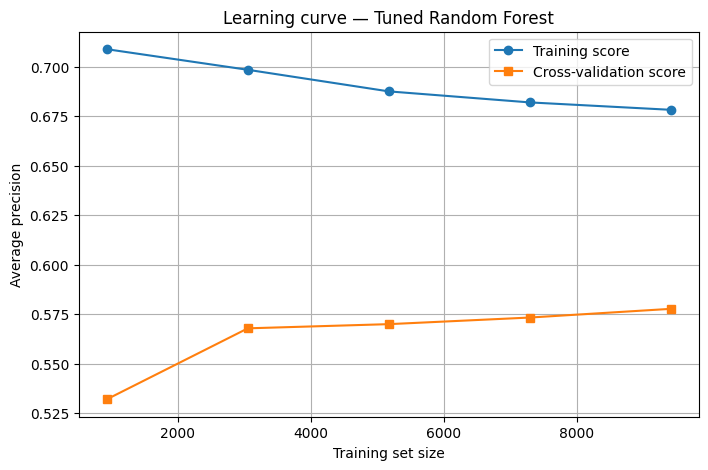

Training set sizes: [ 940 3057 5174 7291 9409]
Training average precision: [0.7089 0.6985 0.6875 0.682  0.6782]
Cross-validation average precision: [0.5319 0.5678 0.5699 0.5732 0.5776]


In [32]:
# Calclate the learning curve using average precision
train_sizes, train_scores, val_scores = learning_curve(
  estimator=best_model_tuned,
  X=X_train,
  y=y_train,
  train_sizes=np.linspace(0.1, 1.0, 5),
  scoring="average_precision",
  cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED),
  n_jobs=-1,
)

train_mean = train_scores.mean(axis=1)
val_mean = val_scores.mean(axis=1)

# Plot the learning curve
plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_mean, marker="o", label="Training score")
plt.plot(train_sizes, val_mean, marker="s", label="Cross-validation score")
plt.xlabel("Training set size")
plt.ylabel("Average precision")
plt.title("Learning curve — Tuned Random Forest")
plt.legend()
plt.grid(True)
plt.show()

# Print the numerical values
print("Training set sizes:", train_sizes)
print("Training average precision:", np.round(train_mean, 4))
print("Cross-validation average precision:", np.round(val_mean, 4))

From the plotting of training and cross validation performance as a function of training dataset size, we can see that the model is overfitting given the wide gap between the two scores. Perhaps chosing fewer trees or a just simpler model could help.

## Section 14: Tensorflow/Keras Data Preparation
For neural networks, we will need to prepare the data differently since they require numerical arrays rather than pandas dataframes.

They also utilize a different mechanism of loading data from what we have already seen with scikit-learn pipelines. The existing preprocessing approach we used of median imputation, scaling of numerical features, one hot encoding and so on will remain unchanged and we will clone the `preprocessor`. We shall then wrap the arrays in `tf.data.Dataset` objects for easy shuffling, batching and prefetching.

In [11]:
# Clone the preprocessor
preprocessor_tf = clone(preprocessor)

# Fit on the training set only and transform each split
X_train_enc = preprocessor_tf.fit_transform(X_train).astype("float32")
X_val_enc = preprocessor_tf.transform(X_val).astype("float32")
X_test_enc = preprocessor_tf.transform(X_test).astype("float32")

# Convert targets to numpy arrays
y_train_np = y_train.values.astype("float32")
y_val_np = y_val.values.astype("float32")
y_test_np = y_test.values.astype("float32")

# Record the number of input features for the neural networks
input_dim = X_train_enc.shape[1]

print("Encoded training shape:", X_train_enc.shape)
print("Encoded validation shape:", X_val_enc.shape)
print("Encoded test shape:", X_test_enc.shape)
print("Number of input features:", input_dim)

# Build tf.data pipelines
BATCH_SIZE = 256

train_ds = (
  tf.data.Dataset.from_tensor_slices((X_train_enc, y_train_np))
  .shuffle(buffer_size=len(X_train_enc), seed=SEED)
  .batch(BATCH_SIZE)
  .prefetch(tf.data.AUTOTUNE)
)

val_ds = (
  tf.data.Dataset.from_tensor_slices((X_val_enc, y_val_np))
  .batch(BATCH_SIZE)
  .prefetch(tf.data.AUTOTUNE)
)

test_ds = (
  tf.data.Dataset.from_tensor_slices((X_test_enc, y_test_np))
  .batch(BATCH_SIZE)
  .prefetch(tf.data.AUTOTUNE)
)

print("tf.data pipelines created.")

Encoded training shape: (14114, 40)
Encoded validation shape: (4705, 40)
Encoded test shape: (4705, 40)
Number of input features: 40
tf.data pipelines created.


## Section 15: Baseline Neural Network
The network of choice is a perceptron of multiple layers. 64 and 32 units, ReLu activation and 1 sigmoid output unit. The sigmoid output unit produces a probability score between 0 and 1 for the positive class ("Yes" on the `bank_account` column).

In [13]:
# Helper to evaluate a Keras model using the same metrics as the traditional models
def evaluate_keras_model(model, X_data, y_true, dataset_name="dataset"):
  y_prob = model.predict(X_data, verbose=0).ravel()
  y_pred = (y_prob >= 0.5).astype(int)
  results = {
    "dataset": dataset_name,
    "accuracy": accuracy_score(y_true, y_pred),
    "precision": precision_score(y_true, y_pred, zero_division=0),
    "recall": recall_score(y_true, y_pred, zero_division=0),
    "f1": f1_score(y_true, y_pred, zero_division=0),
    "roc_auc": roc_auc_score(y_true, y_prob),
    "average_precision": average_precision_score(y_true, y_prob),
  }
  return results

# Helper to build the baseline network
def build_baseline_nn(input_dim):
    model = keras.Sequential([
        keras.layers.Input(shape=(input_dim,)),
        keras.layers.Dense(64, activation="relu"),
        keras.layers.Dense(32, activation="relu"),
        keras.layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=["accuracy", keras.metrics.AUC(name="auc")],
    )
    return model

# Clear any previous Keras state and build the model
keras.backend.clear_session()
tf.random.set_seed(SEED)

model_baseline_nn = build_baseline_nn(input_dim)
model_baseline_nn.summary()

# Early stopping callback
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
)

# Train the model
history_baseline_nn = model_baseline_nn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    callbacks=[early_stop],
    verbose=2,
)

# Evaluate on the validation set
nn_baseline_val_results = evaluate_keras_model(
    model_baseline_nn, X_val_enc, y_val_np, dataset_name="validation"
)

print_metrics(nn_baseline_val_results,
              title="\nBaseline Neural Network — Validation results:"
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,737 (18.50 KB)

 Trainable params: 4,737 (18.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
56/56 - 6s - 102ms/step - accuracy: 0.7739 - auc: 0.5608 - loss: 0.4861 - val_accuracy: 0.8591 - val_auc: 0.8093 - val_loss: 0.3567
Epoch 2/50
56/56 - 1s - 10ms/step - accuracy: 0.8658 - auc: 0.8297 - loss: 0.3272 - val_accuracy: 0.8767 - val_auc: 0.8456 - val_loss: 0.3049
Epoch 3/50
56/56 - 0s - 7ms/step - accuracy: 0.8827 - auc: 0.8500 - loss: 0.2943 - val_accuracy: 0.8803 - val_auc: 0.8593 - val_loss: 0.2898
Epoch 4/50
56/56 - 1s - 11ms/step - accuracy: 0.8850 - auc: 0.8571 - loss: 0.2863 - val_accuracy: 0.8818 - val_auc: 0.8629 - val_loss: 0.2864
Epoch 5/50
56/56 - 0s - 7ms/step - accuracy: 0.8881 - auc: 0.8616 - loss: 0.2825 - val_accuracy: 0.8835 - val_auc: 0.8648 - val_loss: 0.2842
Epoch 6/50
56/56 - 0s - 4ms/step - accuracy: 0.8884 - auc: 0.8648 - loss: 0.2807 - val_accuracy: 0.8833 - val_auc: 0.8638 - val_loss: 0.2848
Epoch 7/50
56/56 - 0s - 4ms/step - accuracy: 0.8883 - auc: 0.8655 - loss: 0.2790 - val_accuracy: 0.8829 - val_auc: 0.8659 - val_loss: 0.2830
Epoch 8/5

- From the results output we can conclude that the Baseline Neural Network is the better overall model, mainly due to its higher score of recall and f1 score on the imbalanced minority positive class. This is achieved with zero hyperparameter tuning as opposed to the random forest that has undergone rigorous hyperparameter tuning using the `RandomizedSearchCV` to search for the optimal settings to yield the best result.
- Additionally we can see that we trained up to epoch 17 out of a possible 50. This early stop is due to the fact that through a carefull monitoring of validation loss against training loss we can stop the model before it overfits by watching for divergence between the 2 losses.

## Section 16: Regularized Neural Network
We can combat the problem of overfitting through dropout and L2 regularisation. If successfully done, this should open door for more epochs and overall better performance.
- **Dropout Rate (0.3)**: This will randomly turn off 30% of the neurons and their connections at each step or batch. This should force our network to learn robust and redudant representations that should generalize better.
- **L2 Regularization**: It will add a penalty proportional to the squared magnitude of the weights which will descourage large weights in the network.

In [14]:
def build_regularized_nn(input_dim):
  model = keras.Sequential([
    keras.layers.Input(shape=(input_dim,)),
    keras.layers.Dense(
      64, activation="relu",
      kernel_regularizer=regularizers.l2(0.001),
    ),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(
      32, activation="relu",
      kernel_regularizer=regularizers.l2(0.001),
    ),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(1, activation="sigmoid"),
  ])
  model.compile(
      optimizer=keras.optimizers.Adam(learning_rate=0.0005),
      loss="binary_crossentropy",
      metrics=["accuracy", keras.metrics.AUC(name="auc")],
  )
  return model

keras.backend.clear_session()
tf.random.set_seed(SEED)

model_regularized_nn = build_regularized_nn(input_dim)
model_regularized_nn.summary()

early_stop_reg = keras.callbacks.EarlyStopping(
  monitor="val_loss",
  patience=5,
  restore_best_weights=True,
)

history_regularized_nn = model_regularized_nn.fit(
  train_ds,
  validation_data=val_ds,
  epochs=50,
  callbacks=[early_stop_reg],
  verbose=2,
)

nn_regularized_val_results = evaluate_keras_model(
  model_regularized_nn, X_val_enc, y_val_np, dataset_name="validation"
)

print_metrics(nn_regularized_val_results,
              title="\nRegularized Neural Network — Validation results:")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,737 (18.50 KB)

 Trainable params: 4,737 (18.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
56/56 - 2s - 33ms/step - accuracy: 0.7772 - auc: 0.5157 - loss: 0.6050 - val_accuracy: 0.8591 - val_auc: 0.7053 - val_loss: 0.4676
Epoch 2/50
56/56 - 0s - 4ms/step - accuracy: 0.8591 - auc: 0.6643 - loss: 0.4663 - val_accuracy: 0.8591 - val_auc: 0.7891 - val_loss: 0.4300
Epoch 3/50
56/56 - 0s - 4ms/step - accuracy: 0.8594 - auc: 0.7418 - loss: 0.4343 - val_accuracy: 0.8591 - val_auc: 0.8205 - val_loss: 0.4024
Epoch 4/50
56/56 - 0s - 4ms/step - accuracy: 0.8635 - auc: 0.7857 - loss: 0.4079 - val_accuracy: 0.8676 - val_auc: 0.8383 - val_loss: 0.3811
Epoch 5/50
56/56 - 0s - 4ms/step - accuracy: 0.8691 - auc: 0.8032 - loss: 0.3929 - val_accuracy: 0.8763 - val_auc: 0.8484 - val_loss: 0.3666
Epoch 6/50
56/56 - 0s - 4ms/step - accuracy: 0.8742 - auc: 0.8168 - loss: 0.3809 - val_accuracy: 0.8808 - val_auc: 0.8540 - val_loss: 0.3564
Epoch 7/50
56/56 - 0s - 5ms/step - accuracy: 0.8774 - auc: 0.8242 - loss: 0.3717 - val_accuracy: 0.8816 - val_auc: 0.8583 - val_loss: 0.3493
Epoch 8/50
5

- From the results we see that the regularized neural network only marginally improves over the baseline. We see a higher ROC-AUC and average precision. It also eliminates overfitting as we are able to train up to epoch 50 without triggering an early stop. On the down side we see a drop in f1, precision, and recall.

## Section 17: Class-Weighted Neural Network
A class weighted neural networks use a different loss function that enforces a higher penalty on errors made on the minority positive class.

In [16]:
# Compute balanced class weights from the training labels only
classes_in_train = np.unique(y_train_np)
class_weight_values = compute_class_weight(
  class_weight="balanced",
  classes=classes_in_train,
  y=y_train_np,
)
class_weights = {int(c): float(w) for c, w in zip(classes_in_train, class_weight_values)}

print("Computed class weights:", class_weights)

keras.backend.clear_session()
tf.random.set_seed(SEED)

model_weighted_nn = build_baseline_nn(input_dim)
model_weighted_nn.summary()

early_stop_w = keras.callbacks.EarlyStopping(
  monitor="val_loss",
  patience=5,
  restore_best_weights=True,
)

history_weighted_nn = model_weighted_nn.fit(
  train_ds,
  validation_data=val_ds,
  epochs=50,
  callbacks=[early_stop_w],
  class_weight=class_weights,
  verbose=2,
)

nn_weighted_val_results = evaluate_keras_model(
  model_weighted_nn, X_val_enc, y_val_np, dataset_name="validation"
)

print_metrics(nn_weighted_val_results,
              title="\nClass-Weighted Neural Network — Validation results:"
)

Computed class weights: {0: 0.5819246309887028, 1: 3.551585304479114}


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,737 (18.50 KB)

 Trainable params: 4,737 (18.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
56/56 - 3s - 46ms/step - accuracy: 0.6764 - auc: 0.7291 - loss: 0.6191 - val_accuracy: 0.7477 - val_auc: 0.8207 - val_loss: 0.5315
Epoch 2/50
56/56 - 0s - 9ms/step - accuracy: 0.7643 - auc: 0.8437 - loss: 0.4922 - val_accuracy: 0.7802 - val_auc: 0.8587 - val_loss: 0.4789
Epoch 3/50
56/56 - 0s - 8ms/step - accuracy: 0.7838 - auc: 0.8591 - loss: 0.4650 - val_accuracy: 0.8185 - val_auc: 0.8606 - val_loss: 0.4311
Epoch 4/50
56/56 - 1s - 12ms/step - accuracy: 0.7904 - auc: 0.8625 - loss: 0.4594 - val_accuracy: 0.7783 - val_auc: 0.8623 - val_loss: 0.4745
Epoch 5/50
56/56 - 0s - 8ms/step - accuracy: 0.7916 - auc: 0.8670 - loss: 0.4530 - val_accuracy: 0.8028 - val_auc: 0.8637 - val_loss: 0.4437
Epoch 6/50
56/56 - 1s - 11ms/step - accuracy: 0.7921 - auc: 0.8680 - loss: 0.4507 - val_accuracy: 0.7915 - val_auc: 0.8643 - val_loss: 0.4574
Epoch 7/50
56/56 - 0s - 7ms/step - accuracy: 0.8025 - auc: 0.8711 - loss: 0.4467 - val_accuracy: 0.7692 - val_auc: 0.8645 - val_loss: 0.4935
Epoch 8/50

- The class-weighted neural network trades high precision for recall. It achieves nearlydouble the positive class capture to 72% and achieves the highest f1 score(0.5297) accross all tested models. This is all at the expense of ROC-AUC (dropped to 86% from 87%) and average precision (dropped from 57% to 55%)

## Section 18: Neural Netowrk Learning Curves


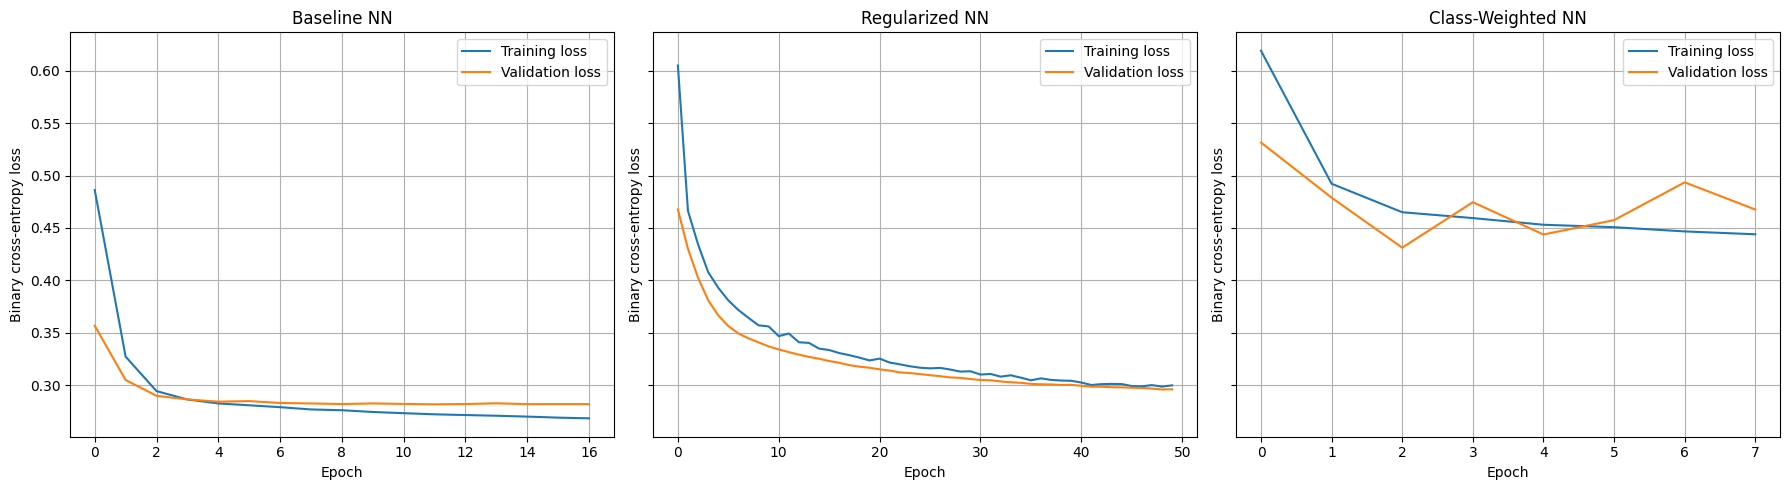

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

histories = [
  ("Baseline NN", history_baseline_nn),
  ("Regularized NN", history_regularized_nn),
  ("Class-Weighted NN", history_weighted_nn)
]

for ax, (title, history) in zip(axes, histories):
  ax.plot(history.history["loss"], label="Training loss")
  ax.plot(history.history["val_loss"], label="Validation loss")
  ax.set_title(title)
  ax.set_xlabel("Epoch")
  ax.set_ylabel("Binary cross-entropy loss")
  ax.legend()
  ax.grid(True)

plt.tight_layout()
plt.show()

- In the baseline plot, both the training and validation losses drop steadily in the 2 epochs and converge. This convergence is maintained through epoch 10 when it starts to diverge as validation loss begins to climb slowly. This is a tail tail sign of `overfitting` and by epoch 17 the divergence is significant enough to trigger the early stopping callback to stop training.

- Introducing dropout rate and L2 regularization in the second graph, again starts off with a steady fall of both training and validation losses and a close convergence is maintained throughout the training period all the to epoch 50. The lack of divergence in the losses shows that as expected dropout rate and L2 regularization managed to eliminate overfitting and complete all epochs without triggering early stopping.

- In graph 3, we added class weighting in order to better handle the imbalanced dataset. The aim was to ensure that the loss function imposed a heavy penalty on errors made on the minority positive class. Because of lack of dropout and regularization, penalizing minority errors more heavily causes the eratic oscillations in the validation loss and by epoch 7 early stopping is triggered.

## Section 19: Experiment Comparison Table

Here we combine every experiment into one table that allows see to compare performance of all models including the traditional ones.

The experiments are:
1. Baseline Logistic Regression
2. Class-Weighted Logistic Regression.
3. Random Forest With Defualt Hyperparameters (expect `n_estimators=200`).
4. Extremely Randomized Trees With Default Hyperparameters (except `n_estimators=200`).
5. Tuned Random Forest With `RandomizedSearchCV`.
6. Baseline Neural Network.
7. Regularized Neural Network.
8. Class-Weighted Neural Network.

In [33]:
# Build the experiment table from the recorded result dictionaries.
experiment_rows = [
  {
    "experiment": 1,
    "model": "Logistic Regression (baseline)",
    "type": "Traditional",
    "split": "60/20/20 stratified",
    "imbalance_handling": "None",
    "key_hyperparameters": "max_iter=1000",
    **{k: v for k, v in baseline_val_results.items() if k != "dataset"},
  },
  {
    "experiment": 2,
    "model": "Logistic Regression (balanced)",
    "family": "Traditional",
    "type": "60/20/20 stratified",
    "imbalance_handling": "class_weight='balanced'",
    "key_hyperparameters": "max_iter=1000, class_weight='balanced'",
    **{k: v for k, v in weighted_val_results.items() if k != "dataset"},
  },
  {
    "experiment": 3,
    "model": "Random Forest (defaults)",
    "type": "Traditional",
    "split": "60/20/20 stratified",
    "imbalance_handling": "None",
    "key_hyperparameters": "n_estimators=200",
    **{k: v for k, v in rf_val_results.items() if k != "dataset"},
  },
  {
    "experiment": 4,
    "model": "Extra Trees (defaults)",
    "type": "Traditional",
    "split": "60/20/20 stratified",
    "imbalance_handling": "None",
    "key_hyperparameters": "n_estimators=200",
    **{k: v for k, v in et_val_results.items() if k != "dataset"},
  },
  {
    "experiment": 5,
    "model": "Random Forest (tuned)",
    "type": "Traditional",
    "split": "60/20/20 stratified",
    "imbalance_handling": "None",
    "key_hyperparameters": str(random_search.best_params_),
    **{k: v for k, v in tuned_val_results.items() if k != "dataset"},
  },
  {
    "experiment": 6,
    "model": "Neural Network (baseline)",
    "type": "Deep Learning",
    "split": "60/20/20 stratified",
    "imbalance_handling": "None",
    "key_hyperparameters": "64-32 hidden, ReLU, Adam lr=0.001, bs=256",
    **{k: v for k, v in nn_baseline_val_results.items() if k != "dataset"},
  },
  {
    "experiment": 7,
    "model": "Neural Network (regularized)",
    "type": "Deep Learning",
    "split": "60/20/20 stratified",
    "imbalance_handling": "None",
    "key_hyperparameters": "64-32 hidden, ReLU, Dropout=0.3, L2=0.001, Adam lr=0.0005",
    **{k: v for k, v in nn_regularized_val_results.items() if k != "dataset"},
  },
  {
    "experiment": 8,
    "model": "Neural Network (class-weighted)",
    "type": "Deep Learning",
    "split": "60/20/20 stratified",
    "imbalance_handling": "class_weight='balanced'",
    "key_hyperparameters": "64-32 hidden, ReLU, Adam lr=0.001, bs=256",
    **{k: v for k, v in nn_weighted_val_results.items() if k != "dataset"},
  },
]

# Convert to a DataFrame and sort by average precision descending
experiment_table = pd.DataFrame(experiment_rows)
experiment_table = experiment_table.sort_values(
    by="average_precision", ascending=False
).reset_index(drop=True)

# Round numeric columns for display
numeric_cols_to_round = ["accuracy", "precision", "recall", "f1", "roc_auc", "average_precision"]
experiment_table[numeric_cols_to_round] = experiment_table[numeric_cols_to_round].round(4)

# Display the table
pd.set_option("display.max_colwidth", 60)
print(experiment_table.to_string(index=False))

 experiment                           model                type               split      imbalance_handling                                                                                                                     key_hyperparameters  accuracy  precision  recall     f1  roc_auc  average_precision      family
          5           Random Forest (tuned)         Traditional 60/20/20 stratified                    None {'classifier__max_depth': None, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 7, 'classifier__n_estimators': 373}    0.8840     0.6997  0.3092 0.4289   0.8656             0.5826         NaN
          7    Neural Network (regularized)       Deep Learning 60/20/20 stratified                    None                                                                               64-32 hidden, ReLU, Dropout=0.3, L2=0.001, Adam lr=0.0005    0.8840     0.6594  0.3650 0.4699   0.8700             0.5737         NaN
          6       Neural Network (baseli

- Looking at the comparison table, we can see that the Neural Netowrk architectures delivered the best overall performance with the regularized neural network in particular achieving a ROC-AUC of 0.8700 followed closely by the baseline MLP with ROC-AUC of 0.8678. Interstingly though, adding dropout and L2 regularization on provided marginal improvements meaning that the original baseline MLP was not severely overfitting.

- Hypeparameter tuning provided the largest improvement with ROC-AUC going from 0.8146 to 0.8656 and the area under the precision recall curve (PR-AUC) going from 0.4839 to 0.5826.

- Experiment 4 (Extremely Randomized Trees) performed worse with ROC-AUC falling from 0.8146 to 0.7692 and PR-AUC 0.4839 to 0.3828 indicating the randomized split point selection couldn't reliably find good decision boundaries in this dataset

- The baseline logistic regression proved interestingly competitive with a ROC-AUC of 0.8570 only 0.013 off the best regularized neural network.

## Section 20: ROC And Precision-Recall Curves


Positive prevalence in validation set: 0.1409


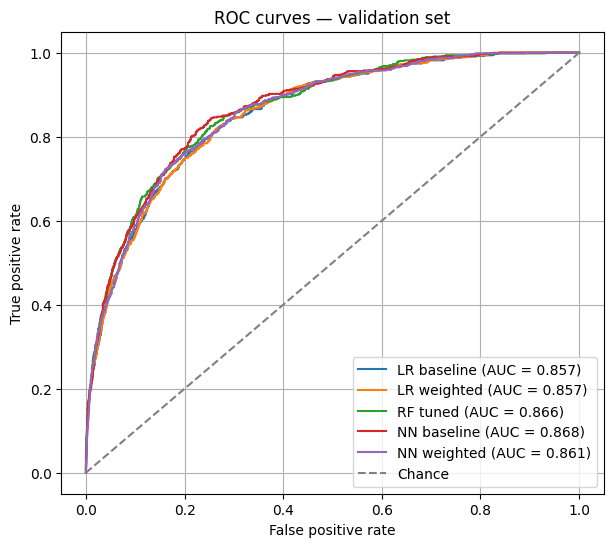

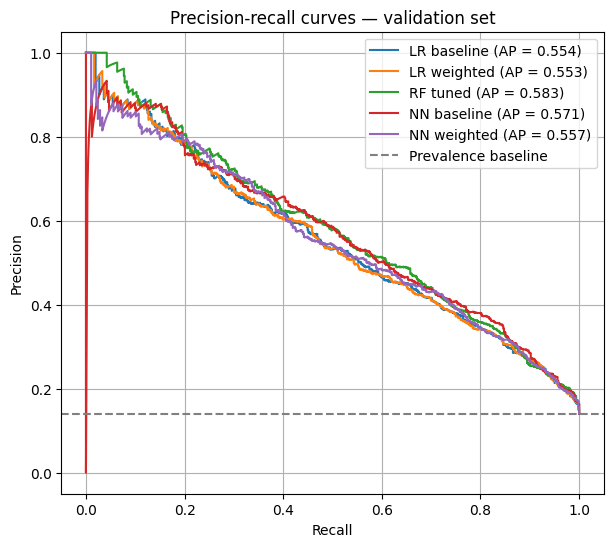

In [35]:
# validation probabilities from each model
val_probabilities = {
    "LR baseline": baseline_lr.predict_proba(X_val)[:, 1],
    "LR weighted": weighted_lr.predict_proba(X_val)[:, 1],
    "RF tuned": best_model_tuned.predict_proba(X_val)[:, 1],
    "NN baseline": model_baseline_nn.predict(X_val_enc, verbose=0).ravel(),
    "NN weighted": model_weighted_nn.predict(X_val_enc, verbose=0).ravel(),
}

# the PR-curve baseline
positive_prevalence = y_val.mean()
print("Positive prevalence in validation set:", round(positive_prevalence, 4))

# ROC curves
plt.figure(figsize=(7, 6))
for name, probs in val_probabilities.items():
    fpr, tpr, _ = roc_curve(y_val, probs)
    auc_value = roc_auc_score(y_val, probs)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_value:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Chance")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curves — validation set")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

# precision-recall curves
plt.figure(figsize=(7, 6))
for name, probs in val_probabilities.items():
    precision, recall, _ = precision_recall_curve(y_val, probs)
    ap_value = average_precision_score(y_val, probs)
    plt.plot(recall, precision, label=f"{name} (AP = {ap_value:.3f})")
plt.axhline(positive_prevalence, linestyle="--", color="grey", label="Prevalence baseline")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-recall curves — validation set")
plt.legend(loc="upper right")
plt.grid(True)
plt.show()

- In the ROC curves, we can see that all models perform relatively the same appart from the diagonal line which represents chance or coin flip. Idealy, we would want the curves to be as close as possible to the top left corner which represents 100% of positives. The true positive y axis means out of all the actual positive cases (meaning survey corespondant having a bank account) how many did the model actually identify.

- In the precision-recall curve, the focus is entirely on the minority positive class. The y axis is the precision (When the model predicts a positive case, how many times is it actually correct). The x axis is the recall (Out of all positive cases, how mnay did the model find). Idealy we want the curves to be in the top right corner meaning every single positive was captured with zero false alarms. The tradeoff is clear, if we want to catch more positives then precision will have to fall.

## Section 21: Confusion Matrix

A confusion matrix helps us visualize the 4 outcomes of a binary classification. True positives (TP), True negatives(TN), Flase negatives(FN), and False positives(FP).

Selected model: Regularized NN
True negatives (TN):  3917
False positives (FP): 125
False negatives (FN): 421
True positives (TP):  242


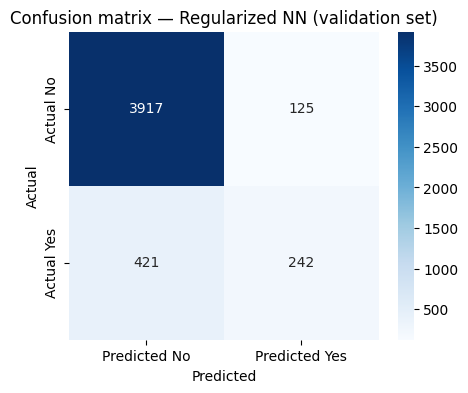

In [40]:
selected_model_name = "best_nn"

if selected_model_name == "tuned_rf":
  selected_model_display_name = "Tuned Random Forest"
  y_val_pred_selected = best_model_tuned.predict(X_val)
  y_val_prob_selected = best_model_tuned.predict_proba(X_val)[:, 1]
elif selected_model_name == "best_nn":
  # Pick the neural network with the highest validation average precision
  nn_candidates = {
    "Baseline NN": (model_baseline_nn, nn_baseline_val_results["average_precision"]),
    "Regularized NN": (model_regularized_nn, nn_regularized_val_results["average_precision"]),
    "Weighted NN": (model_weighted_nn, nn_weighted_val_results["average_precision"]),
  }
  nn_choice_name, (nn_choice_model, _) = max(
    nn_candidates.items(), key=lambda item: item[1][1]
  )
  selected_model_display_name = nn_choice_name
  y_val_prob_selected = nn_choice_model.predict(X_val_enc, verbose=0).ravel()
  y_val_pred_selected = (y_val_prob_selected >= 0.5).astype(int)
else:
  raise ValueError("selected_model_name must be 'tuned_rf' or 'best_nn'.")

# Compute the confusion matrix
cm = confusion_matrix(y_val, y_val_pred_selected, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

print(f"Selected model: {selected_model_display_name}")
print(f"True negatives (TN):  {tn}")
print(f"False positives (FP): {fp}")
print(f"False negatives (FN): {fn}")
print(f"True positives (TP):  {tp}")

# Plot the confusion matrix
plt.figure(figsize=(5, 4))
sns.heatmap(
  cm, annot=True, fmt="d", cmap="Blues",
  xticklabels=["Predicted No", "Predicted Yes"],
  yticklabels=["Actual No", "Actual Yes"],
)
plt.title(f"Confusion matrix — {selected_model_display_name} (validation set)")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.show()

## Section 22: Saving The Models


In [42]:
# Save the best traditional model
joblib.dump(best_model_tuned, "best_traditional_model.joblib")
print("Saved best_traditional_model.joblib")

# Save the selected neural network
best_nn_model = model_regularized_nn
best_nn_model.save("best_nn_model.keras")
print("Saved best_nn_model.keras")

# Save the experiment table
experiment_table.to_csv("experiment_table.csv", index=False)
print("Saved experiment_table.csv")

# Upload the files to Google Drive
from google.colab import drive
drive.mount("/content/drive")

drive_folder = "/content/drive/MyDrive/ml_summative"
os.makedirs(drive_folder, exist_ok=True)

for filename in ["best_traditional_model.joblib", "best_nn_model.keras", "experiment_table.csv"]:
    shutil.copy(filename, os.path.join(drive_folder, filename))
    print(f"Copied {filename} to {drive_folder}")

Saved best_traditional_model.joblib
Saved best_nn_model.keras
Saved experiment_table.csv
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Copied best_traditional_model.joblib to /content/drive/MyDrive/ml_summative
Copied best_nn_model.keras to /content/drive/MyDrive/ml_summative
Copied experiment_table.csv to /content/drive/MyDrive/ml_summative
